# ДЗ 1. Рекомендации товаров Amazon Video Games

Сравниваю ItemKNN, iALS, EASE, FM и ALS с таргетом из оценки и давности отзыва. Для каждого пользователя нужно выбрать десять ещё не оценённых товаров. Попаданием считаю товар, которому он позже поставит 4 или 5.

В Video Games входят игры, консоли и аксессуары. Один объект — товар с отдельным ASIN. Отзыв говорит о знакомстве с товаром; данных о самой покупке здесь нет.

Запуск из папки `hw:

```bash
python3 -m venv .venv
source .venv/bin/activate
pip install -r requirements.txt
python run_notebook.py
```

Данные загружаются автоматически при запуске ноутбука.

In [1]:
from pathlib import Path
import os

Path(".cache/matplotlib").mkdir(parents=True, exist_ok=True)
os.environ["MPLCONFIGDIR"] = str(Path(".cache/matplotlib").resolve())
os.environ["OMP_NUM_THREADS"] = "2"
os.environ["OPENBLAS_NUM_THREADS"] = "2"
os.environ["MKL_NUM_THREADS"] = "2"

import json
import platform
from importlib.metadata import version

import numpy as np
import pandas as pd
import scipy
from scipy import sparse
import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import torch
from threadpoolctl import threadpool_limits
from io import BytesIO
from IPython.display import display, Image


def show_plot(fig):
    image = BytesIO()
    fig.savefig(image, format="png", bbox_inches="tight")
    display(Image(data=image.getvalue()))


SEED = 42
K = 10
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(2)
torch.use_deterministic_algorithms(True)
thread_limits = threadpool_limits(limits=2)
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "font.size": 10,
    }
)
pd.set_option("display.max_colwidth", 180)
pd.set_option("display.precision", 5)
Path("results").mkdir(exist_ok=True)

from data_utils import (
    SOURCE,
    FILES,
    TRAIN_END,
    VALID_END,
    MAX_ITEMS,
    MIN_TRAIN_INTERACTIONS,
    download_data,
    file_hashes,
    load_ratings,
    select_cohort,
    load_metadata,
    category_features,
    interaction_matrix,
    split_audit,
)
from evaluation import evaluation_set, paired_bootstrap
from experiment_utils import GRIDS, tune, final_comparison

print(
    f"Python {platform.python_version()}, NumPy {np.__version__}, "
    f"PyTorch {torch.__version__}; seed={SEED}, CPU threads=2"
)

Python 3.13.5, NumPy 2.5.2, PyTorch 2.9.0; seed=42, CPU threads=2


## 1. Данные

Взял полный файл оценок Amazon Reviews 2014, Video Games: [страница датасета](https://cseweb.ucsd.edu/~jmcauley/datasets/amazon/links.html). Оценки и метаданные скачиваются из [архива SNAP](https://snap.stanford.edu/data/amazon/productGraph/categoryFiles/). Готовую 5-core выборку не использую: отбор пользователей и товаров делаю по train.

В `ratings_Video_Games.csv` 1 324 753 строки. `user_id` — ID автора отзыва, `item_id` — ASIN товара, `rating` — оценка от 1 до 5, `timestamp` — время отзыва в секундах Unix. В `meta_Video_Games.json.gz` есть названия и категории. Этот файл записан как Python literals, поэтому читаю его через `ast.literal_eval`.

Для FM беру категории. Поля `salesRank` и `also_bought` могли накопить информацию из будущего относительно train, поэтому в признаки их не включаю.

In [2]:
data_dir = download_data("data/raw")
hashes = file_hashes(data_dir)
raw, clean, audit = load_ratings(data_dir)

source_summary = pd.Series(
    {
        "Исходные строки": audit["raw_rows"],
        "Пользователи": audit["raw_users"],
        "Товары": audit["raw_items"],
        "Полные дубликаты строк": audit["duplicate_rows"],
        "Повторные пары user–item": audit["duplicate_pairs"],
        "Некорректные rating/timestamp после dropna": audit["invalid_rows"],
        "Строки после очистки": audit["clean_rows"],
    },
    name="Количество",
)
display(source_summary.to_frame())
display(pd.Series(audit["missing"], name="Пропуски").to_frame())
print(
    "Временной диапазон:",
    pd.to_datetime(clean.timestamp.min(), unit="s", utc=True),
    "—",
    pd.to_datetime(clean.timestamp.max(), unit="s", utc=True),
)
display(pd.Series(hashes, name="SHA-256").to_frame())

,Количество
Исходные строки,1324753
Пользователи,826767
Товары,50210
Полные дубликаты строк,0
Повторные пары user–item,0
Некорректные rating/timestamp после dropna,0
Строки после очистки,1324753


,Пропуски
user_id,0
item_id,0
rating,0
timestamp,0


Временной диапазон: 1997-11-08 00:00:00+00:00 — 2014-07-23 00:00:00+00:00


,SHA-256
ratings_Video_Games.csv,f0ca171050c2e0f208d47f5267992476b21ab68a01439c21c8be1a4432982cfa
meta_Video_Games.json.gz,b7bf4c724632874b931056e48957775822c6f0c9092f5bbf2d449694bec36180


## 2. Подготовка и EDA

В очистке убираю пропуски, оценки вне [1, 5] и неположительный timestamp. Если на пару user–item приходится несколько отзывов, оставляю первый: повторная оценка уже знакомого товара не должна попасть в проверку новых рекомендаций.

EASE хранит плотную матрицу связей между товарами, поэтому ограничиваю каталог. По отзывам до 1 июля 2013 года выбираю 4000 самых популярных товаров, затем пользователей с хотя бы тремя оценками в этом каталоге. При равной популярности сортирую товары по ASIN. После отбора пользователей удаляю товары без train-взаимодействий.

Так получается выборка активных пользователей и популярных товаров. Будущие отзывы на отбор не влияют; менее активные пользователи и остальной каталог в эксперимент не входят.

In [3]:
selected, train, valid, test, user_ids, item_ids = select_cohort(clean)
shape = (len(user_ids), len(item_ids))

volumes = pd.DataFrame(
    [
        {
            "Этап": "Исходный файл",
            "Взаимодействия": len(raw),
            "Пользователи": raw.user_id.nunique(),
            "Товары": raw.item_id.nunique(),
        },
        {
            "Этап": "После очистки",
            "Взаимодействия": len(clean),
            "Пользователи": clean.user_id.nunique(),
            "Товары": clean.item_id.nunique(),
        },
        {
            "Этап": "Выбранная когорта",
            "Взаимодействия": len(selected),
            "Пользователи": shape[0],
            "Товары": shape[1],
        },
    ]
).set_index("Этап")
display(volumes)
assert 100_000 <= len(selected) <= 2_000_000
assert min(shape) >= 1_000
assert train.timestamp.max() < TRAIN_END <= valid.timestamp.min()
assert valid.timestamp.max() < VALID_END <= test.timestamp.min()

activity = train.groupby("user").size()
popularity = train.groupby("item").size()
density = len(train) / (shape[0] * shape[1])
print(
    f"Заполненность train: {100 * density:.4f}%; разреженность: {100 * (1 - density):.4f}%"
)
display(
    pd.concat(
        [
            activity.describe().rename("Оценок на пользователя"),
            popularity.describe().rename("Оценок на товар"),
        ],
        axis=1,
    )
)

,Взаимодействия,Пользователи,Товары
Этап,,,
Исходный файл,1324753,826767,50210
После очистки,1324753,826767,50210
Выбранная когорта,186358,33616,3997


Заполненность train: 0.1323%; разреженность: 99.8677%


,Оценок на пользователя,Оценок на товар
count,33616.00000,3997.00000
mean,5.28704,44.46560
std,6.65354,53.22325
min,3.00000,1.00000
25%,3.00000,17.00000
50%,4.00000,29.00000
75%,5.00000,49.00000
max,479.00000,681.00000


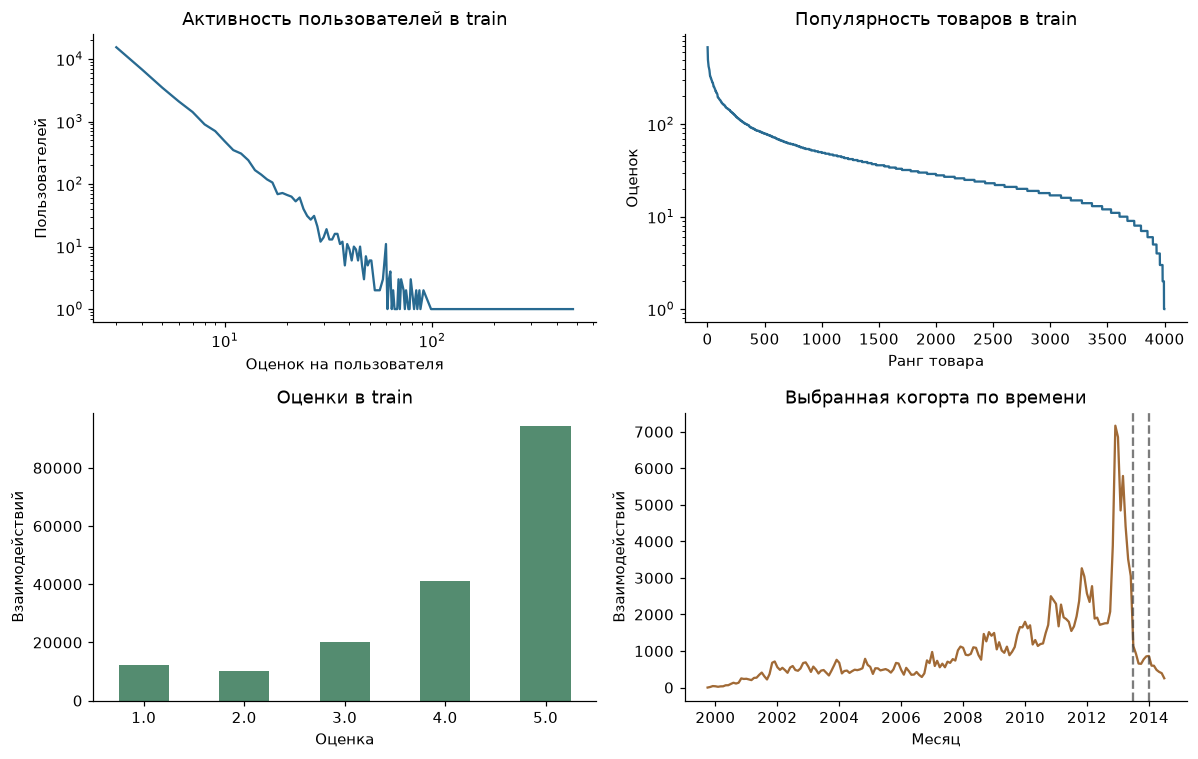

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
activity.value_counts().sort_index().plot(
    ax=axes[0, 0], logx=True, logy=True, color="#286a91"
)
axes[0, 0].set(
    xlabel="Оценок на пользователя",
    ylabel="Пользователей",
    title="Активность пользователей в train",
)
axes[0, 1].plot(
    np.arange(1, len(popularity) + 1),
    popularity.sort_values(ascending=False).to_numpy(),
    color="#286a91",
)
axes[0, 1].set(
    xlabel="Ранг товара",
    ylabel="Оценок",
    yscale="log",
    title="Популярность товаров в train",
)
train.rating.value_counts().sort_index().plot.bar(ax=axes[1, 0], color="#548c70", rot=0)
axes[1, 0].set(xlabel="Оценка", ylabel="Взаимодействий", title="Оценки в train")
monthly = selected.groupby(
    pd.to_datetime(selected.timestamp, unit="s", utc=True).dt.strftime("%Y-%m")
).size()
month_dates = pd.to_datetime(monthly.index)
axes[1, 1].plot(month_dates, monthly.to_numpy(), color="#a16a36")
for boundary in (TRAIN_END, VALID_END):
    axes[1, 1].axvline(
        pd.to_datetime(boundary, unit="s"), color="#444444", linestyle="--", alpha=0.7
    )
axes[1, 1].set(
    xlabel="Месяц", ylabel="Взаимодействий", title="Выбранная когорта по времени"
)
fig.tight_layout()
show_plot(fig)
plt.close(fig)

В категории обычно указаны платформа и тип товара: PC, PlayStation, Games, Accessories. Проверю, улучшат ли эти признаки рекомендации. Для FM кодирую категории как multi-hot с весом $1/\sqrt{m_i}$, где $m_i$ — число категорий товара. Общую категорию Video Games убираю, для пропусков добавляю отдельный признак. Словарь фиксирую по train-каталогу.

Платформу и тип товара считаю статическими свойствами, известными при рекомендации. Это допущение: в датасете один снимок метаданных, и проверить, какие теги были у товара на историческую дату, нельзя.

,Значение
Записей в исходном файле метаданных,50953.00000
Товаров в выбранном каталоге,3997.00000
Без названия,3825.00000
Без категорий,30.00000
"Признаков категорий, включая missing",161.00000
Среднее число категорий,2.89942


,title,categories
0,,"[Games, PC]"
1,,"[Accessories, Controllers, Microphones, PlayStation 3, Wii]"
2,,"[Accessories, Cables, Cables & Adapters, Wii]"
3,,"[Accessories, Hardware, More Systems, Nintendo 64]"
4,,"[Accessories, Xbox 360]"
5,"2 Pack - Gator Crunch Wii Gamecube 6FT Extension Cable / Cord (Lifetime Warranty, Bulk packaging)",[Wii]


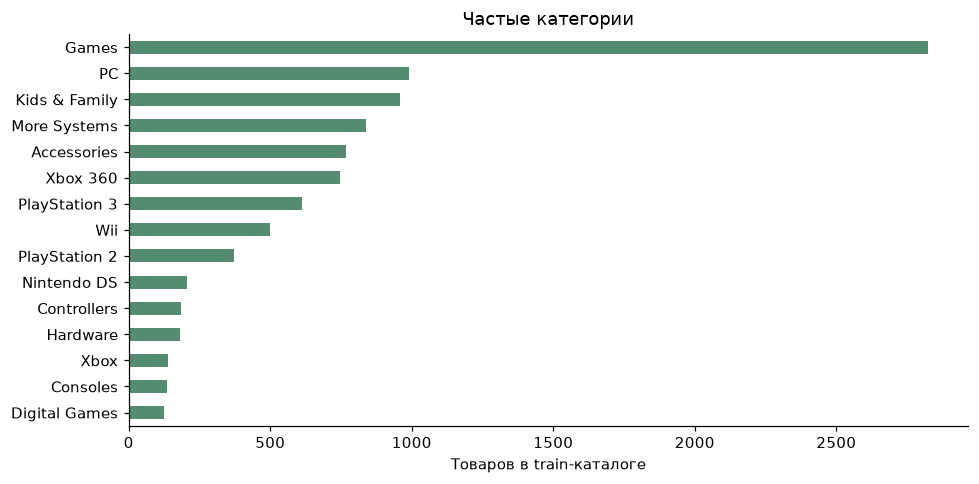

In [5]:
metadata, metadata_rows = load_metadata(data_dir, item_ids)
features, vocabulary = category_features(metadata)
category_count = metadata.categories.map(len)
metadata_audit = pd.Series(
    {
        "Записей в исходном файле метаданных": metadata_rows,
        "Товаров в выбранном каталоге": len(metadata),
        "Без названия": int(metadata.title.eq("").sum()),
        "Без категорий": int(category_count.eq(0).sum()),
        "Признаков категорий, включая missing": features.shape[1],
        "Среднее число категорий": category_count.mean(),
    },
    name="Значение",
)
display(metadata_audit.to_frame())
display(metadata[["title", "categories"]].head(6))

category_popularity = metadata.categories.explode().dropna().value_counts().head(15)
fig, ax = plt.subplots(figsize=(9, 4.5))
category_popularity.sort_values().plot.barh(ax=ax, color="#548c70")
ax.set(xlabel="Товаров в train-каталоге", ylabel="", title="Частые категории")
fig.tight_layout()
show_plot(fig)
plt.close(fig)

У 3825 из 3997 товаров нет названия, поэтому использовать текст названий здесь неудобно. Категории отсутствуют только у 30 товаров. Всего получился 161 категориальный признак, включая признак пропуска. Самая частая категория — Games; платформы и типы аксессуаров дают более подробное описание товара.

## 3. Протокол оценки

Разбиваю отзывы по общим временным границам:

| Часть | Время отзыва | Для чего используется |
|---|---|---|
| Train | До 2013-07-01 UTC | Отбор данных, признаки, обучение |
| Validation | [2013-07-01, 2014-01-01) UTC | Выбор параметров |
| Test | С 2014-01-01 UTC до конца файла | Финальное сравнение |

После подбора параметров переобучаю модели на train + validation. Набор пользователей, каталог и словарь категорий остаются такими же, как в исходном train.

Каждая модель ранжирует весь выбранный каталог из 3997 товаров. Из кандидатов исключаю все товары, которые пользователь уже оценивал, в том числе низко. При равном score первым идёт меньший item ID; внутренние ID упорядочены по ASIN. Кандидатов при оценке не сэмплирую.

Релевантным считаю новый товар с оценкой ≥4 в будущем периоде. Метрики считаю по пользователям, у которых есть хотя бы один такой товар и не меньше десяти оставшихся кандидатов. У всех моделей одни и те же пользователи, кандидаты и релевантные товары.

Новые пользователи и товары в оценку не входят. В таблице ниже `outside_users` и `outside_items` также включают старых пользователей с недостаточной активностью и товары вне top-4000. Эти два столбца пересекаются; пересечение показано в `outside_both`.

In [6]:
train_valid = pd.concat([train, valid], ignore_index=True)
history_train = interaction_matrix(train, shape, column=None)
history_final = interaction_matrix(train_valid, shape, column=None)
valid_users, valid_relevant = evaluation_set(valid, history_train, shape, k=K)
test_users, test_relevant = evaluation_set(test, history_final, shape, k=K)

audit_splits = split_audit(clean, selected, train, valid, test, user_ids, item_ids)
display(audit_splits)
assert (
    audit_splits.before_cohort
    - audit_splits.outside_users
    - audit_splits.outside_items
    + audit_splits.outside_both
).equals(audit_splits.retained)

evaluation_population = pd.DataFrame(
    [
        {
            "Этап": "Validation",
            "Пользователей с оценками": valid.user.nunique(),
            "Оцениваемых пользователей": len(valid_users),
            "Релевантных пар у оцениваемых пользователей": valid_relevant[
                valid_users
            ].nnz,
            "Медиана кандидатов": np.median(
                shape[1] - history_train[valid_users].getnnz(axis=1)
            ),
        },
        {
            "Этап": "Test",
            "Пользователей с оценками": test.user.nunique(),
            "Оцениваемых пользователей": len(test_users),
            "Релевантных пар у оцениваемых пользователей": test_relevant[
                test_users
            ].nnz,
            "Медиана кандидатов": np.median(
                shape[1] - history_final[test_users].getnnz(axis=1)
            ),
        },
    ]
).set_index("Этап")
display(evaluation_population)
assert len(valid_users) > 0 and len(test_users) > 0
print("Оценка идёт по полному каталогу без сэмплирования кандидатов.")

,before_cohort,retained,outside_users,outside_items,outside_both,users,items,positive_rows
split,,,,,,,,
train,920802,177729,678389,319961,255277,33616,3997,135256
validation,181942,5003,169392,101976,94429,2677,1773,3900
test,222009,3626,211034,140748,133399,1943,1490,2827


,Пользователей с оценками,Оцениваемых пользователей,Релевантных пар у оцениваемых пользователей,Медиана кандидатов
Этап,,,,
Validation,2677,2214,3900,3992.0
Test,1943,1595,2827,3992.0


Оценка идёт по полному каталогу без сэмплирования кандидатов.


Основной метрикой для подбора выбираю NDCG@10: важно не только попасть в интересы пользователя, но и поставить подходящий товар ближе к началу списка. Recall@10 показывает, какую долю его будущих положительных оценок удалось найти. Обе метрики усредняю по пользователям.

Для множества релевантных товаров $H_u$ и списка рекомендаций $L_u$:

$$
\operatorname{Recall@10}_u=\frac{|L_u\cap H_u|}{|H_u|},\qquad
\operatorname{NDCG@10}_u=
\frac{\sum_{r=1}^{10}\mathbf 1[L_{u,r}\in H_u]/\log_2(r+1)}
{\sum_{r=1}^{\min(10,|H_u|)}1/\log_2(r+1)}.
$$

Для дополнительного сравнения считаю HitRate@10 — долю пользователей с попаданием, и Coverage@10 — долю каталога, попавшую в рекомендации. Параметры по ним не подбираю.

Здесь проверяется совпадение с будущими отзывами. Если отзыва нет, неизвестно, понравился бы товар пользователю.

## 4. Модели и подбор параметров

### ItemKNN

Строю бинарную матрицу $X$: $X_{ui}=1$, если пользователь оценил товар на 4 или 5. Для двух товаров считаю число общих пользователей $n_{ij}=X_{:i}^{\top}X_{:j}$ и cosine similarity со shrinkage:

$$
s_{ij}=\frac{n_{ij}}{\sqrt{n_i n_j}}\frac{n_{ij}}{n_{ij}+\beta},\qquad s_{ii}=0.
$$

Здесь $n_i$ — число положительных оценок товара. Shrinkage уменьшает сходство, если общих пользователей мало. Для каждого кандидата оставляю $k$ ближайших товаров. В матрице $B$ строки соответствуют товарам из истории, столбцы — кандидатам; итоговый score равен $X_uB$.

Код: `models/item_knn.py`.

### iALS

На наблюдаемых парах задаю $p_{ui}=\mathbf 1[r_{ui}\ge4]$ и $c_{ui}=1+\alpha$, на пропусках — $p_{ui}=0,c_{ui}=1$. Так низкая оценка штрафуется сильнее, чем неизвестная пара. Функция потерь:

$$
\sum_{u,i}c_{ui}(p_{ui}-x_u^\top y_i)^2+
\lambda\left(\sum_u\|x_u\|^2+\sum_i\|y_i\|^2\right).
$$

При фиксированных факторах товаров обновляю пользователя:

$$
x_u=\left[Y^\top Y+\alpha\sum_{i\in O_u}y_i y_i^\top+\lambda I\right]^{-1}
(1+\alpha)\sum_{i\in O_u}p_{ui}y_i.
$$

В $O_u$ входят все его оценки, включая низкие. В коде решаю линейную систему, затем аналогично обновляю факторы товаров. Для ранжирования использую $x_u^\top y_i$.

Код: `models/ials.py`.

### EASE

Использую ту же бинарную матрицу $X$, что и для ItemKNN:

$$
\min_{\operatorname{diag}(B)=0}\|X-XB\|_F^2+\lambda\|B\|_F^2.
$$

Обозначим $P=(X^\top X+\lambda I)^{-1}$. Тогда $B_{ij}=-P_{ij}/P_{jj}$ при $i\ne j$, а $B_{ii}=0$. Деление идёт по столбцам, отрицательные веса сохраняю. Рекомендации получаю по $X_uB$.

Для вычисления $P$ использую разложение Холецкого. Плотная матрица требует $O(n_{items}^2)$ памяти, её факторизация — $O(n_{items}^3)$ времени. Это причина ограничить каталог четырьмя тысячами товаров.

Код: `models/ease.py`.

### FM с категориями

Вектор $z$ состоит из one-hot user ID, one-hot item ID и категорий товара. FM учитывает линейные слагаемые и попарные взаимодействия:

$$
f(z)=w_0+\sum_a w_a z_a+\sum_{a<b}\langle v_a,v_b\rangle z_a z_b.
$$

В сумму входят также пары item–category и category–category. Считаю её через тождество:

$$
\sum_{a<b}\langle v_a,v_b\rangle z_a z_b=
\frac12\sum_f\left[\left(\sum_a v_{af}z_a\right)^2-\sum_a v_{af}^2z_a^2\right].
$$

Метка наблюдаемой пары равна $1[r\ge4]$. На каждую такую пару добавляю один случайный неизвестный товар того же пользователя с меткой 0. Выбор равномерный, с исключением всех уже оценённых им товаров. Будущие отзывы при сэмплировании не проверяю, поэтому часть отрицательных примеров может оказаться будущими положительными. Сэмпл фиксирован на все эпохи одного обучения.

Обучаю FM по BCE с L2-регуляризацией, используя Adam и autograd из PyTorch. Для ранжирования достаточно логитов. После обучения заранее считаю слагаемые, зависящие только от товара, чтобы быстрее оценивать весь каталог.

Код: `models/fm.py`.

### ALS с новым таргетом

В обычном iALS оценки 4 и 5 дают одинаковый таргет, а 1, 2 и 3 превращаются в ноль. Попробую сохранить знак и силу оценки, а старые отзывы учитывать слабее:

$$
p^*_{ui}=\frac{r_{ui}-3}{2}\left(\frac12+\frac12\,2^{-a_{ui}/h}\right),\qquad
 a_{ui}=\frac{T-t_{ui}}{86400},\quad h=365\text{ дней}.
$$

Для пропусков $p^*_{ui}=0$. Возраст отзыва считаю от границы обучения $T$: 2013-07-01 при подборе и 2014-01-01 после переобучения. Оценки 1–2 дают отрицательный таргет, 3 — ноль, 4–5 — положительный. Множитель давности лежит между 0.5 и 1, поэтому старые оценки не исчезают полностью.

Меняется только $p$ в правой части ALS-системы. Confidence и функция потерь остаются прежними. Хочу проверить, даст ли такой сигнал лучшие рекомендации, чем бинарный порог.

Код: `models/custom_als.py`. Кроме отдельно настроенной модели, сравню её с iALS при одинаковых параметрах (`CustomALS matched`). Для FM тоже сделаю сравнение без категорий при тех же настройках (`FM IDs matched`) и отдельно подберу вариант без категорий (`FM IDs`).

На validation проверяю 23 конфигурации, включая FM без категорий. Выбираю максимум NDCG@10; при равенстве — больший Recall@10, затем более раннюю конфигурацию в сетке. Seed, число итераций, negative ratio и период полураспада зафиксированы заранее.

| Модель | Параметры поиска |
|---|---|
| ItemKNN | $k\in\{50,150\}$, shrinkage $\in\{0,20\}$ |
| iALS | factors $\in\{32,64\}$, reg $\in\{1,10\}$; alpha=20, 15 итераций |
| EASE | reg $\in\{50,200,800\}$ |
| FM | factors $\in\{16,32\}$, L2 $\in\{10^{-5},10^{-4}\}$; lr=0.01, 12 эпох, batch=4096 |
| CustomALS | Та же сетка factors/reg, alpha=20, 15 итераций; half-life=365 дней |
| FM IDs | Та же сетка FM, без категорий |

Сетку ограничил, чтобы можно было повторить эксперимент на CPU. Все конфигурации обучаются на полном выбранном train и оцениваются на всех подходящих validation-пользователях.

In [7]:
search_space = pd.DataFrame(
    [
        {"model": name, "trial": trial, "params": json.dumps(params, sort_keys=True)}
        for name, grid in GRIDS.items()
        for trial, params in enumerate(grid)
    ]
)
display(search_space)
print("Число validation fits:", len(search_space))
assert len(search_space) == 23

validation_results, selected_params = tune(
    train,
    shape,
    features,
    TRAIN_END,
    valid_users,
    valid_relevant,
    history_train,
    output="results",
)

,model,trial,params
0,ItemKNN,0,"{""k"": 50, ""shrinkage"": 0}"
1,ItemKNN,1,"{""k"": 50, ""shrinkage"": 20}"
2,ItemKNN,2,"{""k"": 150, ""shrinkage"": 0}"
3,ItemKNN,3,"{""k"": 150, ""shrinkage"": 20}"
4,iALS,0,"{""alpha"": 20, ""factors"": 32, ""iterations"": 15, ""reg"": 1, ""seed"": 42}"
5,iALS,1,"{""alpha"": 20, ""factors"": 32, ""iterations"": 15, ""reg"": 10, ""seed"": 42}"
6,iALS,2,"{""alpha"": 20, ""factors"": 64, ""iterations"": 15, ""reg"": 1, ""seed"": 42}"
7,iALS,3,"{""alpha"": 20, ""factors"": 64, ""iterations"": 15, ""reg"": 10, ""seed"": 42}"
8,EASE,0,"{""reg"": 50}"
9,EASE,1,"{""reg"": 200}"


Число validation fits: 23


ItemKNN    1/4  NDCG=0.03795  Recall=0.06303  fit=0.1s


ItemKNN    2/4  NDCG=0.04389  Recall=0.06936  fit=0.1s


ItemKNN    3/4  NDCG=0.03892  Recall=0.06293  fit=0.2s


...

CustomALS  4/4  NDCG=0.04678  Recall=0.07656  fit=18.2s


FM IDs     1/4  NDCG=0.03692  Recall=0.06376  fit=4.0s


FM IDs     2/4  NDCG=0.02667  Recall=0.03824  fit=3.8s


FM IDs     3/4  NDCG=0.03721  Recall=0.06275  fit=5.6s


FM IDs     4/4  NDCG=0.02667  Recall=0.03824  fit=5.5s


In [8]:
validation_columns = ["model", "trial", "NDCG@10", "Recall@10", "fit_seconds", "params"]
display(
    validation_results[validation_columns]
    .sort_values(["model", "NDCG@10"], ascending=[True, False])
    .reset_index(drop=True)
)

display(
    pd.DataFrame(
        [
            {"model": name, "selected parameters": json.dumps(params, sort_keys=True)}
            for name, params in selected_params.items()
        ]
    )
)
selected_path = Path("results/selected_params.json")
assert selected_path.exists()
assert json.loads(selected_path.read_text()) == selected_params
print("Настройки записаны в", selected_path, "до финального сравнения на test.")

,model,trial,NDCG@10,Recall@10,fit_seconds,params
0,CustomALS,3,0.04678,0.07656,18.16012,"{""alpha"": 20, ""factors"": 64, ""half_life_days"": 365, ""iterations"": 15, ""reg"": 10, ""seed"": 42}"
1,CustomALS,2,0.04650,0.07560,18.12357,"{""alpha"": 20, ""factors"": 64, ""half_life_days"": 365, ""iterations"": 15, ""reg"": 1, ""seed"": 42}"
2,CustomALS,1,0.04648,0.07851,10.29996,"{""alpha"": 20, ""factors"": 32, ""half_life_days"": 365, ""iterations"": 15, ""reg"": 10, ""seed"": 42}"
3,CustomALS,0,0.04506,0.07687,10.41330,"{""alpha"": 20, ""factors"": 32, ""half_life_days"": 365, ""iterations"": 15, ""reg"": 1, ""seed"": 42}"
4,EASE,0,0.05302,0.08410,0.85953,"{""reg"": 50}"
5,EASE,1,0.05126,0.08342,0.77908,"{""reg"": 200}"
6,EASE,2,0.04823,0.07796,0.74807,"{""reg"": 800}"
7,FM,1,0.03116,0.05480,9.63761,"{""batch_size"": 4096, ""epochs"": 12, ""factors"": 16, ""lr"": 0.01, ""negative_ratio"": 1, ""seed"": 42, ""weight_decay"": 0.0001}"
8,FM,3,0.03058,0.05538,14.29405,"{""batch_size"": 4096, ""epochs"": 12, ""factors"": 32, ""lr"": 0.01, ""negative_ratio"": 1, ""seed"": 42, ""weight_decay"": 0.0001}"
9,FM,2,0.02661,0.05087,14.37138,"{""batch_size"": 4096, ""epochs"": 12, ""factors"": 32, ""lr"": 0.01, ""negative_ratio"": 1, ""seed"": 42, ""weight_decay"": 1e-05}"


,model,selected parameters
0,ItemKNN,"{""k"": 150, ""shrinkage"": 20}"
1,iALS,"{""alpha"": 20, ""factors"": 64, ""iterations"": 15, ""reg"": 1, ""seed"": 42}"
2,EASE,"{""reg"": 50}"
3,FM,"{""batch_size"": 4096, ""epochs"": 12, ""factors"": 16, ""lr"": 0.01, ""negative_ratio"": 1, ""seed"": 42, ""weight_decay"": 0.0001}"
4,CustomALS,"{""alpha"": 20, ""factors"": 64, ""half_life_days"": 365, ""iterations"": 15, ""reg"": 10, ""seed"": 42}"
5,FM IDs,"{""batch_size"": 4096, ""epochs"": 12, ""factors"": 32, ""lr"": 0.01, ""negative_ratio"": 1, ""seed"": 42, ""use_metadata"": false, ""weight_decay"": 1e-05}"
6,CustomALS matched,"{""alpha"": 20, ""factors"": 64, ""half_life_days"": 365, ""iterations"": 15, ""reg"": 1, ""seed"": 42}"
7,FM IDs matched,"{""batch_size"": 4096, ""epochs"": 12, ""factors"": 16, ""lr"": 0.01, ""negative_ratio"": 1, ""seed"": 42, ""use_metadata"": false, ""weight_decay"": 0.0001}"


Настройки записаны в results/selected_params.json до финального сравнения на test.


## 5. Результаты на test

Параметры выбраны и сохранены. Переобучаю модели на train + validation и считаю test-метрики. Для нового таргета ALS пересчитываю возраст отзывов относительно 2014-01-01. Каталог и правила оценки остаются прежними.

In [9]:
# Evaluate on test after choosing the parameters.
results, per_user_test, fm_losses = final_comparison(
    selected_params,
    train_valid,
    shape,
    features,
    VALID_END,
    test_users,
    test_relevant,
    history_final,
    output="results",
)

main_models = ["ItemKNN", "iALS", "EASE", "FM", "CustomALS"]
metric_columns = [
    "NDCG@10",
    "Recall@10",
    "HitRate@10",
    "Coverage@10",
    "fit_seconds",
    "evaluation_seconds",
    "params",
]
main_results = results.loc[main_models, metric_columns].sort_values(
    "NDCG@10", ascending=False
)
display(main_results)
assert (results.users == len(test_users)).all()
main_results.to_csv("results/main_comparison.csv")

ItemKNN            NDCG=0.04232  Recall=0.07289


iALS               NDCG=0.04342  Recall=0.07436


EASE               NDCG=0.04968  Recall=0.08249


FM                 NDCG=0.04046  Recall=0.07437


CustomALS          NDCG=0.04403  Recall=0.07620


FM IDs             NDCG=0.04134  Recall=0.06963


CustomALS matched  NDCG=0.04293  Recall=0.07239


FM IDs matched     NDCG=0.03642  Recall=0.07204


,NDCG@10,Recall@10,HitRate@10,Coverage@10,fit_seconds,evaluation_seconds,params
model,,,,,,,
EASE,0.04968,0.08249,0.12476,0.50788,0.85143,0.75194,"{""reg"": 50}"
CustomALS,0.04403,0.07620,0.11411,0.25069,19.04828,0.36650,"{""alpha"": 20, ""factors"": 64, ""half_life_days"": 365, ""iterations"": 15, ""reg"": 10, ""seed"": 42}"
iALS,0.04342,0.07436,0.11285,0.30173,19.47302,0.35791,"{""alpha"": 20, ""factors"": 64, ""iterations"": 15, ""reg"": 1, ""seed"": 42}"
ItemKNN,0.04232,0.07289,0.11034,0.53615,0.15743,0.14668,"{""k"": 150, ""shrinkage"": 20}"
FM,0.04046,0.07437,0.10157,0.02702,9.28700,0.35643,"{""batch_size"": 4096, ""epochs"": 12, ""factors"": 16, ""lr"": 0.01, ""negative_ratio"": 1, ""seed"": 42, ""weight_decay"": 0.0001}"


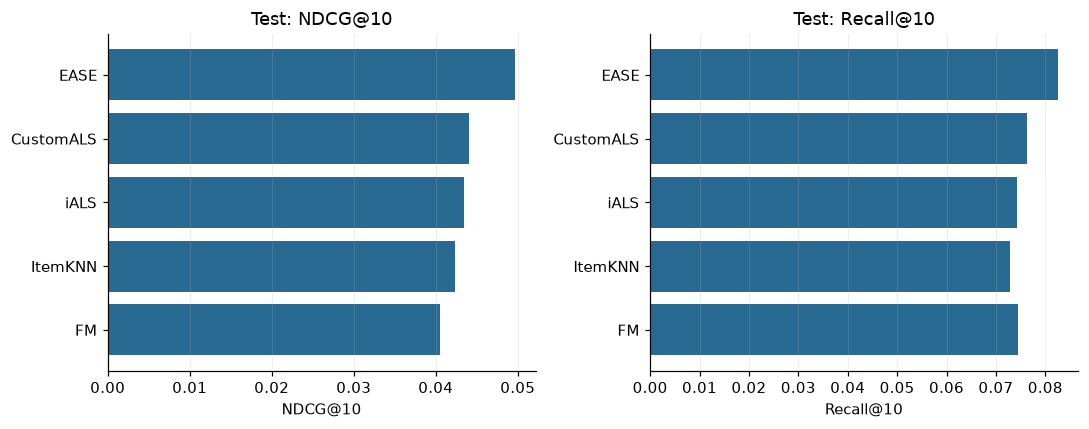

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
order = main_results.index[::-1]
for ax, metric in zip(axes, ["NDCG@10", "Recall@10"]):
    values = results.loc[order, metric]
    ax.barh(order, values, color="#286a91")
    ax.set(xlabel=metric, title=f"Test: {metric}")
    ax.grid(axis="x", alpha=0.2)
fig.tight_layout()
show_plot(fig)
plt.close(fig)

В паре `CustomALS matched` / iALS одинаковы число факторов, регуляризация, confidence, число итераций и seed. В паре FM / `FM IDs matched` совпадают параметры обучения, отрицательные примеры и начальные ID-векторы. Так можно отдельно посмотреть на изменение таргета и добавление категорий.

Для разницы NDCG@10 считаю 95% bootstrap-интервал: 2000 раз выбираю пользователей с возвращением, сохраняя пары их результатов. Этот интервал учитывает разброс между пользователями данного test, но не смену seed, периода или настроек. Если он пересекает ноль, уверенного вывода об улучшении сделать нельзя.

In [11]:
ablation_names = [
    "iALS",
    "CustomALS matched",
    "CustomALS",
    "FM",
    "FM IDs matched",
    "FM IDs",
]
display(results.loc[ablation_names, ["NDCG@10", "Recall@10", "params"]])

contrasts = [
    ("Custom target при настройках iALS", "CustomALS matched", "iALS"),
    ("Категории при настройках FM", "FM", "FM IDs matched"),
]
bootstrap_rows = []
for label, first, second in contrasts:
    estimate = paired_bootstrap(
        per_user_test[first], per_user_test[second], seed=SEED, repeats=2000
    )
    bootstrap_rows.append(
        {
            "Сравнение": label,
            "Первая модель": first,
            "Вторая модель": second,
            **estimate,
        }
    )
bootstrap_results = pd.DataFrame(bootstrap_rows).set_index("Сравнение")
display(bootstrap_results)
bootstrap_results.to_csv("results/paired_bootstrap.csv")

,NDCG@10,Recall@10,params
model,,,
iALS,0.04342,0.07436,"{""alpha"": 20, ""factors"": 64, ""iterations"": 15, ""reg"": 1, ""seed"": 42}"
CustomALS matched,0.04293,0.07239,"{""alpha"": 20, ""factors"": 64, ""half_life_days"": 365, ""iterations"": 15, ""reg"": 1, ""seed"": 42}"
CustomALS,0.04403,0.07620,"{""alpha"": 20, ""factors"": 64, ""half_life_days"": 365, ""iterations"": 15, ""reg"": 10, ""seed"": 42}"
FM,0.04046,0.07437,"{""batch_size"": 4096, ""epochs"": 12, ""factors"": 16, ""lr"": 0.01, ""negative_ratio"": 1, ""seed"": 42, ""weight_decay"": 0.0001}"
FM IDs matched,0.03642,0.07204,"{""batch_size"": 4096, ""epochs"": 12, ""factors"": 16, ""lr"": 0.01, ""negative_ratio"": 1, ""seed"": 42, ""use_metadata"": false, ""weight_decay"": 0.0001}"
FM IDs,0.04134,0.06963,"{""batch_size"": 4096, ""epochs"": 12, ""factors"": 32, ""lr"": 0.01, ""negative_ratio"": 1, ""seed"": 42, ""use_metadata"": false, ""weight_decay"": 1e-05}"


,Первая модель,Вторая модель,difference,ci_low,ci_high
Сравнение,,,,,
Custom target при настройках iALS,CustomALS matched,iALS,-0.00049,-0.00700,0.00578
Категории при настройках FM,FM,FM IDs matched,0.00404,-0.00174,0.00964


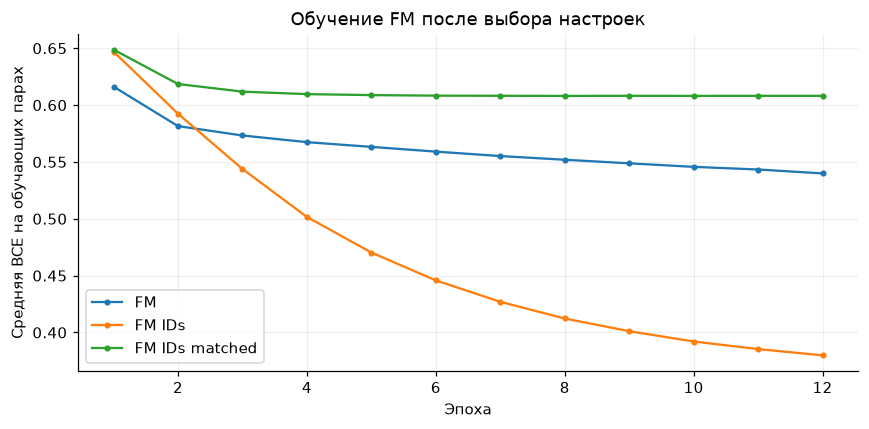

In [12]:
fig, ax = plt.subplots(figsize=(8, 4))
for name, values in fm_losses.items():
    ax.plot(np.arange(1, len(values) + 1), values, marker="o", markersize=3, label=name)
ax.set(
    xlabel="Эпоха",
    ylabel="Средняя BCE на обучающих парах",
    title="Обучение FM после выбора настроек",
)
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()
show_plot(fig)
plt.close(fig)
# BCE without the L2 penalty. Lower training loss may not improve NDCG.

In [13]:
manifest = {
    "seed": SEED,
    "k": K,
    "primary_metric": "NDCG@10",
    "source": SOURCE,
    "source_files": list(FILES),
    "sha256": hashes,
    "train_end_utc": pd.to_datetime(TRAIN_END, unit="s", utc=True).isoformat(),
    "valid_end_utc": pd.to_datetime(VALID_END, unit="s", utc=True).isoformat(),
    "cohort": {
        "max_items": MAX_ITEMS,
        "min_train_interactions": MIN_TRAIN_INTERACTIONS,
        "raw_rows": len(raw),
        "clean_rows": len(clean),
        "selected_rows": len(selected),
        "users": shape[0],
        "items": shape[1],
    },
    "evaluation_users": {"validation": len(valid_users), "test": len(test_users)},
    "selected_params": selected_params,
    "python": platform.python_version(),
    "platform": platform.platform(),
    "packages": {
        name: version(name)
        for name in ["numpy", "scipy", "pandas", "matplotlib", "torch", "threadpoolctl"]
    },
    "cpu_threads": 2,
}
Path("results/run_manifest.json").write_text(
    json.dumps(manifest, ensure_ascii=False, indent=2) + "\n"
)
print(
    "Сохранены агрегаты validation/test, выбранные параметры, bootstrap, FM loss и run manifest."
)

Сохранены агрегаты validation/test, выбранные параметры, bootstrap, FM loss и run manifest.


## 6. Выводы

На этом разбиении выиграл EASE с $\lambda=50$: NDCG@10 = 0.04968, Recall@10 = 0.08249. Он опередил iALS по NDCG на 0.00626 и обучился примерно за 0.9 с против 19.5 с у iALS. Для каталога из 3997 товаров это удобный вариант, хотя на большом каталоге плотная матрица станет проблемой.

У ItemKNN помог shrinkage: при 150 соседях validation NDCG вырос с 0.03892 до 0.04428. Для iALS выбраны 64 фактора и reg=1, для CustomALS — 64 фактора и reg=10. У EASE из проверенных значений подошла самая слабая регуляризация: при увеличении reg с 50 до 800 validation NDCG упал с 0.05302 до 0.04823.

Новый таргет ALS улучшения не подтвердил. Отдельно настроенный CustomALS получил NDCG 0.04403 против 0.04342 у iALS, но при одинаковых параметрах результат снизился до 0.04293. Разница равна −0.00049, bootstrap-интервал [−0.00700; 0.00578]. То есть небольшое преимущество настроенной модели нельзя приписать самому таргету. Оценка и давность менялись вместе; отдельный эффект давности я не проверял.

С категориями FM получила NDCG 0.04046, без них при тех же настройках — 0.03642. Разница равна +0.00404, но её интервал [−0.00174; 0.00964] пересекает ноль. Отдельно настроенная FM без категорий дала 0.04134. Поэтому уверенного выигрыша от метаданных здесь тоже нет. Для FM с категориями выбраны 16 факторов и L2=0.0001, без категорий — 32 фактора и L2=0.00001.

Ещё у FM сильно ограничен набор выдаваемых товаров: всего 108, или 2.7% каталога. Для сравнения, EASE рекомендует 2030 товаров (50.8%), ItemKNN — 2143 (53.6%). Уменьшение train BCE само по себе не дало FM преимущества в ранжировании.

Главное ограничение связано с отбором данных. Из 222009 исходных test-отзывов осталось 3626, а метрики посчитаны по 1595 пользователям с новым положительным отзывом. Результаты относятся к этой выборке, а не ко всем посетителям Amazon.

Проверял одно временное разбиение, один seed и небольшую сетку параметров. Новые пользователи и товары исключены, поэтому качество cold-start рекомендаций здесь не оценивалось.

В данных нет показов и заказов. Неизвестные пары для FM могут оказаться подходящими пользователю товарами, на которые он просто не оставил отзыв. Категории взяты из одного снимка; их доступность в прошлом предполагается, но не проверяется.